In [144]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/checking-logs.sqlite")

In [150]:
weekendDaysComms = pd.io.sql.read_sql(
    """
    ---sql
    
    SELECT CAST(strftime('%H', timestamp) AS INT) AS hour
    FROM checker
    WHERE uid NOT LIKE 'admin_%' and strftime('%w', timestamp) in ('0','6')
    """,
    conn,
)
weekendDaysComms = weekendDaysComms["hour"].to_list()
print(*weekendDaysComms)

7 13 13 13 13 13 14 14 14 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 17 17 17 17 17 17 17 18 18 18 18 18 18 18 18 19 19 19 19 19 19 20 20 20 20 21 21 21 21 21 22 22 22 22 22 0 0 5 5 9 9 10 10 10 10 10 10 10 11 11 11 11 11 13 13 13 13 18 18 18 21 21 21 21 21 21 21 21 3 7 7 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8 8 9 9 9 11 11 11 11 11 11 11 11 12 12 12 12 12 12 12 14 14 14 14 15 15 15 15 15 15 15 15 16 16 16 16 16 16 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18 18 18 19 19 19 19 20 20 20 20 20 20 20 20 20 20 21 21 21 21 21 21 21 21 22 22 22 23 0 0 7 7 8 8 8 8 8 8 10 10 10 10 10 10 10 10 10 10 11 11 11 11 11 11 11 11 12 12 12 12 12 12 12 12 12 12 12 12 12 12 13 13 13 13 13 13 14 14 14 14 14 14 14 15 15 15 15 15 15 15 15 15 15 15 15 15 15 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 19 1

In [151]:
workingDaysComms = pd.io.sql.read_sql(
    """
    ---sql
    
    SELECT CAST(strftime('%H', timestamp) AS INT) AS hour
    FROM checker
    WHERE uid NOT LIKE 'admin_%' and strftime('%w', timestamp) NOT IN ('0','6')
    """,
    conn,
)
workingDaysComms = workingDaysComms["hour"].to_list()
print(*workingDaysComms)

5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 11 11 11 11 11 12 12 11 11 14 14 14 15 15 15 15 15 15 15 17 17 17 19 19 19 19 19 19 19 19 19 19 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18 19 19 20 20 20 20 20 20 22 22 12 13 13 13 18 18 18 18 19 19 19 19 19 19 19 19 19 19 20 21 21 21 22 22 22 22 22 22 0 0 7 7 8 8 8 8 11 11 12 12 12 12 13 13 13 13 14 14 14 14 14 20 20 21 21 21 21 21 21 21 21 21 21 21 21 21 21 21 21 21 21 10 10 16 16 17 17 17 17 17 17 17 17 17 17 22 22 3 3 8 8 21 21 11 11 11 11 16 20 20 20 20 20 20 20 20 20 20 20 22 22 22 22 22 22 5 5 7 7 10 10 10 10 10 10 10 10 11 15 15 15 15 18 18 18 18 18 18 18 18 18 18 18 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 6 11 11 11 11 11 11 11 13 13 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 18 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 19 21 21 21 21 22 22 22 22 22 22 22 8 8 8 8 9 10 10 10 10 10 10 12 12 12 12 12 12 12 12 12 12 13 13 14 14 14 14 14 14 14 14 14 14 14 14 15 15 8 9 9 9 9 9 9 9 9 9 9

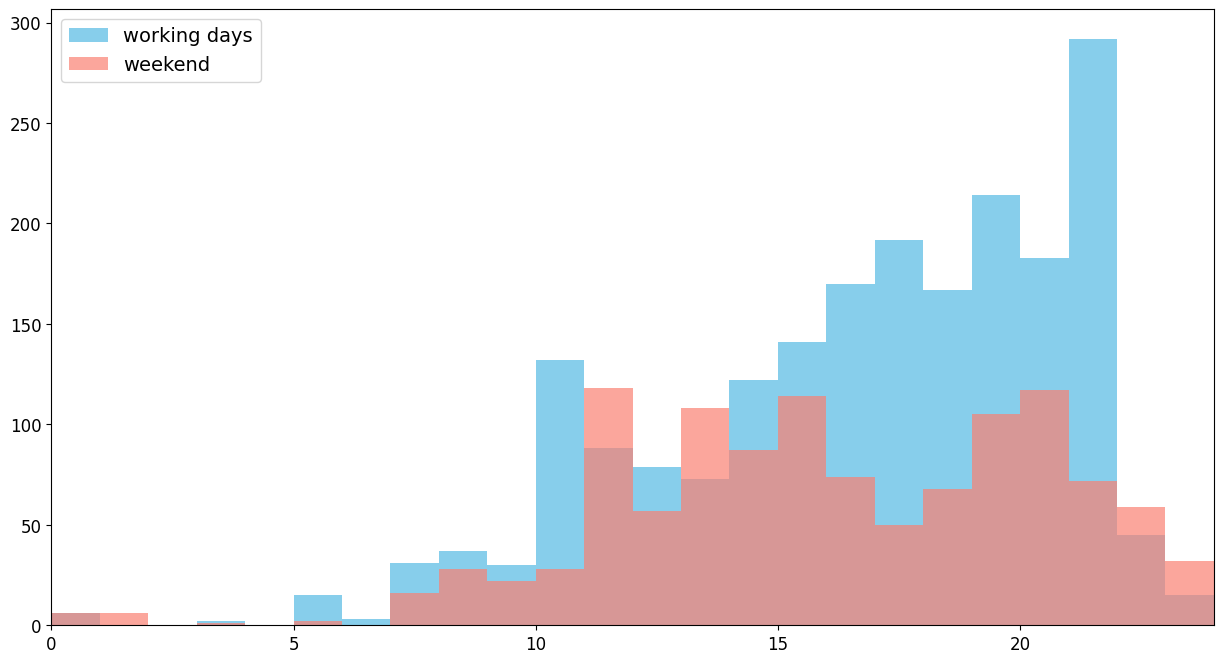

In [147]:
plt.figure(figsize=(15, 8))

plt.hist(
    workingDaysComms, bins=24, range=(0, 24), color="skyblue", label="working days"
)

plt.hist(
    weekendDaysComms,
    bins=24,
    range=(0, 24),
    color="salmon",
    alpha=0.7,
    label="weekend",
)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(loc="upper left", fontsize=14)
plt.xlim(0, 24)
plt.show()

## Есть ли часы, когда общее число коммитов было выше в выходные, чем в рабочие дни?
Да, в 11, 13, 22, 23 часа.

In [ ]:
conn.close()